# Porównanie 4 modeli ML – predykcja bankructwa
HistGradientBoosting, XGBoost, Random Forest, Logistic Regression. Metryka główna: Average Precision (klasy silnie niezbalansowane).

## 1. Biblioteki

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.io import arff

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)
from xgboost import XGBClassifier

## 2. Wczytanie danych

In [3]:
sciezka = Path('5year.arff')
rekordy, meta = arff.loadarff(sciezka)
X = pd.DataFrame({n.replace('Attr', 'X'): rekordy[n].astype(float)
                  for n in rekordy.dtype.names if n != 'class'})
y = pd.Series([int(v.decode('ascii')) for v in rekordy['class']], name='y')
print('Plik:', sciezka.resolve())

Plik: /Users/marysia/Documents/praca_inzynierska/Projekt_inzynierski-main/Bankructwo Polskie firmy/modele/5year.arff


## 3. Kontrola jakości danych

In [4]:
print('Kształt:', X.shape)
print('Typy:', X.dtypes.unique())
print('Klasy:', y.value_counts().to_dict(), f'| bankructwa: {y.mean():.2%}')
print('Wartości inf:', int(np.isinf(X).sum().sum()))
print('Kolumny stałe:', int((X.nunique() <= 1).sum()))
print('Wiersze w pełni puste:', int(X.isna().all(axis=1).sum()))

pelne = pd.concat([X, y], axis=1)
print('Duplikaty (cechy + etykieta):', int(pelne.duplicated().sum()))
print('Duplikaty cech z różną etykietą:', int(pelne.drop_duplicates().duplicated(subset=X.columns).sum()))

Kształt: (5910, 64)
Typy: [dtype('float64')]
Klasy: {0: 5500, 1: 410} | bankructwa: 6.94%
Wartości inf: 0
Kolumny stałe: 0
Wiersze w pełni puste: 0
Duplikaty (cechy + etykieta): 60
Duplikaty cech z różną etykietą: 0


**Wnioski**
- Zbiór ma 5910 firm i 64 wskaźniki, wszystkie numeryczne (float64), więc nie potrzeba kodowania zmiennych.
- Klasy są mocno niezbalansowane: 6,9% bankructw (410 z 5910). Dlatego metryką główną jest Average Precision, a nie accuracy, a baseline AP to około 0,07.
- Brak wartości nieskończonych, kolumn stałych i pustych wierszy, więc dane nie wymagają dodatkowego czyszczenia strukturalnego.
- Jest 60 duplikatów (1%). Usuwamy je przed podziałem na train i test, żeby ta sama firma nie trafiła do obu zbiorów.
- Żaden duplikat nie ma sprzecznej etykiety, więc nie ma konfliktów w danych.

## 4. Brakujące wartości – analiza
Braki wynikają głównie z dzielenia przez zero lub braku historii, nie są losowe:
- X37 (43%) – brak zobowiązań długoterminowych w mianowniku
- X27 – brak kosztów finansowych; X45, X60 – brak zapasów; X28, X53, X54, X64 – brak środków trwałych
- X21 – brak sprzedaży z poprzedniego roku; X24 – brak historii 3 lat

Sprawdzamy, czy sam fakt braku niesie informację o klasie.

In [5]:
braki = X.isna().mean().sort_values(ascending=False)
display(braki[braki > 0].head(10).round(3).to_frame('udział braków'))
print('Kolumny z brakami:', int((braki > 0).sum()), '| wiersze z brakiem:', f'{X.isna().any(axis=1).mean():.1%}')
print('Średnia liczba braków na wiersz:', X.isna().sum(axis=1).groupby(y).mean().round(2).to_dict())
print('ROC-AUC liczby braków vs klasa:', round(roc_auc_score(y, X.isna().sum(axis=1)), 3))

,udział braków
X37,0.431
X27,0.066
X45,0.045
X60,0.045
X24,0.023
X28,0.018
X64,0.018
X53,0.018
X54,0.018
X21,0.017


Kolumny z brakami: 49 | wiersze z brakiem: 48.7%
Średnia liczba braków na wiersz: {0: 0.73, 1: 1.57}
ROC-AUC liczby braków vs klasa: 0.681


## 5. Wartości odstające i współliniowość
Ratio finansowe mają ekstremalne wartości (mianownik bliski zera). Nie usuwamy ich – ekstremum bywa sygnałem upadłości; modele drzewiowe są odporne, a dla regresji logistycznej użyjemy transformacji kwantylowej.

In [6]:
opis = X.describe(percentiles=[.01, .99]).T[['min', '1%', '99%', 'max']]
print('Cechy z |skośnością| > 10:', int((X.skew().abs() > 10).sum()), 'z', X.shape[1])
display(opis.loc[opis['max'].abs().sort_values(ascending=False).index[:5]].round(1))

kor = X.corr(method='spearman').abs()
gora = kor.where(np.triu(np.ones(kor.shape, dtype=bool), 1)).stack()
print('Pary cech o |Spearman| > 0.95:', int((gora > 0.95).sum()))
display(gora.sort_values(ascending=False).head(5).round(3).to_frame('|rho|'))

Cechy z |skośnością| > 10: 63 z 64


,min,1%,99%,max
X60,-12.4,1.3,686.7,4818700.0
X32,-255.1,7.1,997.4,4277200.0
X55,-1118500.0,-46437.9,184742.4,4212200.0
X15,-9632400.0,-21663.6,37792.2,1341700.0
X5,-1076400.0,-708.9,689.9,1250100.0


Pary cech o |Spearman| > 0.95: 34


|rho|
X14 X18  1.000
X7  X14  1.000
    X18  0.999
X20 X60  0.999
X2  X17  0.999

**Wnioski z analizy**
- 63 z 64 wskaźników ma |skośność| > 10. Ratio finansowe mają ciężkie ogony, bo mianownik bywa bliski zera (np. X60: 99. percentyl = 687, maksimum = 4,8 mln).
- Część wartości jest niemożliwa ekonomicznie (np. X32, rotacja w dniach, min = −255), więc w danych są błędy lub artefakty księgowe.
- 34 pary cech mają |Spearman| > 0,95. Wynika to z konstrukcji wskaźników: X7, X14 i X18 to prawie ten sam iloraz zysku do aktywów, a X2 i X17 oraz X20 i X60 są swoimi odwrotnościami.

**Decyzje**
- Outlierów nie usuwamy ani nie obcinamy. Skrajna wartość wskaźnika bywa sygnałem upadłości, a modele drzewiowe są na nią odporne.
- Regresja logistyczna dostaje `QuantileTransformer` zamiast `RobustScaler`, bo przy takich ogonach zwykłe skalowanie nie wystarcza.
- Skorelowanych cech nie usuwamy. Drzewom nie szkodzą, a regresję logistyczną reguluje parametr C.
- Permutation importance interpretujemy ostrożnie, bo przy skorelowanych cechach ważność rozkłada się między nie.

## 6. Duplikaty i podział danych

In [7]:
dane = pelne.drop_duplicates().reset_index(drop=True)
y = dane.pop('y')
X = dane

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print('Po usunięciu duplikatów:', X.shape)
print('Train:', X_train.shape, f'(bankructwa {y_train.mean():.2%})')
print('Test: ', X_test.shape, f'(bankructwa {y_test.mean():.2%})')
print('Baseline AP (losowy klasyfikator):', round(y_train.mean(), 4))

Po usunięciu duplikatów: (5850, 64)
Train: (4680, 64) (bankructwa 6.97%)
Test:  (1170, 64) (bankructwa 7.01%)
Baseline AP (losowy klasyfikator): 0.0697


## 7. Modele

In [8]:
modele = {
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
        min_samples_leaf=30, l2_regularization=1.0, random_state=42),
    'XGBoost': XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
        eval_metric='logloss', tree_method='hist', random_state=42, n_jobs=2),
    'RandomForest': RandomForestClassifier(
        n_estimators=250, max_features='sqrt', min_samples_leaf=3,
        class_weight='balanced_subsample', random_state=42, n_jobs=-1),
    'LogisticRegression': LogisticRegression(
        C=0.2, class_weight='balanced', max_iter=3000, solver='lbfgs', random_state=42)
}

imputery = {
    'mediana': lambda: SimpleImputer(strategy='median'),
    'mediana+wskaźnik': lambda: SimpleImputer(strategy='median', add_indicator=True),
    'stała+wskaźnik': lambda: SimpleImputer(strategy='constant', fill_value=-999, add_indicator=True),
}

def zbuduj(nazwa, imputacja):
    kroki = [('imputer', imputery[imputacja]())]
    if nazwa == 'LogisticRegression':
        kroki.append(('scaler', QuantileTransformer(output_distribution='normal', n_quantiles=500, random_state=42)))
    kroki.append(('model', clone(modele[nazwa])))
    return Pipeline(kroki)

## 8. Wybór strategii imputacji

In [9]:
metryki = {'AP': 'average_precision', 'ROC_AUC': 'roc_auc'}
wszystkie = {}
for nazwa in modele:
    for imp in imputery:
        s = cross_validate(zbuduj(nazwa, imp), X_train, y_train, cv=cv, scoring=metryki, n_jobs=1)
        wszystkie[(nazwa, imp)] = {'AP': s['test_AP'].mean(), 'AP_STD': s['test_AP'].std(), 'ROC_AUC': s['test_ROC_AUC'].mean()}

porownanie = pd.DataFrame(wszystkie).T
display(porownanie['AP'].unstack().round(4))
wybor = porownanie['AP'].unstack().idxmax(axis=1)
print('Wybrana imputacja:', wybor.to_dict())

,mediana,mediana+wskaźnik,stała+wskaźnik
HistGradientBoosting,0.7520,0.7831,0.7791
LogisticRegression,0.4506,0.6659,0.6682
RandomForest,0.4732,0.5543,0.6020
XGBoost,0.7327,0.7686,0.7566


Wybrana imputacja: {'HistGradientBoosting': 'mediana+wskaźnik', 'LogisticRegression': 'stała+wskaźnik', 'RandomForest': 'stała+wskaźnik', 'XGBoost': 'mediana+wskaźnik'}


## 9. Ranking modeli (CV, wybrana imputacja)

In [10]:
finalne = {n: zbuduj(n, wybor[n]) for n in modele}
ranking = pd.DataFrame([{'Model': n, 'Imputacja': wybor[n], **porownanie.loc[(n, wybor[n])]} for n in modele])
ranking = ranking.sort_values('AP', ascending=False).reset_index(drop=True)
display(ranking.round(4))

,Model,Imputacja,AP,AP_STD,ROC_AUC
0,HistGradientBoosting,mediana+wskaźnik,0.7831,0.0409,0.9510
1,XGBoost,mediana+wskaźnik,0.7686,0.0527,0.9459
2,LogisticRegression,stała+wskaźnik,0.6682,0.0665,0.9310
3,RandomForest,stała+wskaźnik,0.6020,0.0507,0.9320


## 10. Ocena na zbiorze testowym

,Model,AP,ROC_AUC,Próg,Precision,Recall,F1
0,HistGradientBoosting,0.8475,0.9697,0.3508,0.8533,0.7805,0.8153
1,XGBoost,0.8297,0.9613,0.3583,0.8310,0.7195,0.7712
2,LogisticRegression,0.7209,0.9435,0.9072,0.6711,0.6220,0.6456
3,RandomForest,0.6532,0.9530,0.3662,0.6087,0.6829,0.6437


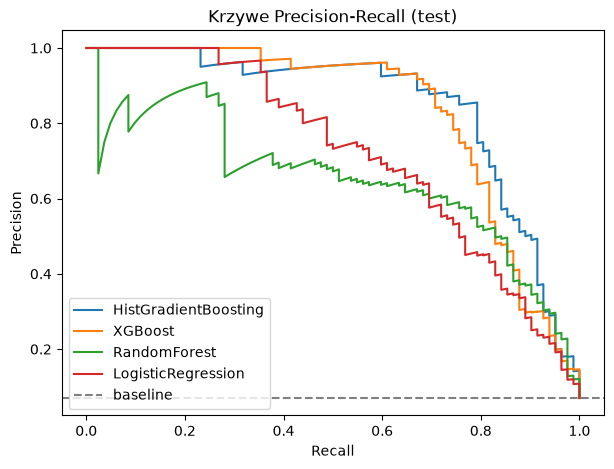

In [11]:
wyniki_test, krzywe = [], {}
for nazwa, p in finalne.items():
    oof = cross_val_predict(clone(p), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    pr, rc, th = precision_recall_curve(y_train, oof)
    prog = th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]

    p.fit(X_train, y_train)
    proba = p.predict_proba(X_test)[:, 1]
    pred = (proba >= prog).astype(int)
    krzywe[nazwa] = precision_recall_curve(y_test, proba)[:2]
    wyniki_test.append({
        'Model': nazwa, 'AP': average_precision_score(y_test, proba), 'ROC_AUC': roc_auc_score(y_test, proba),
        'Próg': prog, 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred)})

wyniki_test = pd.DataFrame(wyniki_test).sort_values('AP', ascending=False).reset_index(drop=True)
display(wyniki_test.round(4))

plt.figure(figsize=(7, 5))
for n, (pr, rc) in krzywe.items():
    plt.plot(rc, pr, label=n)
plt.axhline(y_test.mean(), ls='--', c='gray', label='baseline')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.title('Krzywe Precision-Recall (test)')
plt.show()

## 11. Które wskaźniki mają największy wpływ na model?

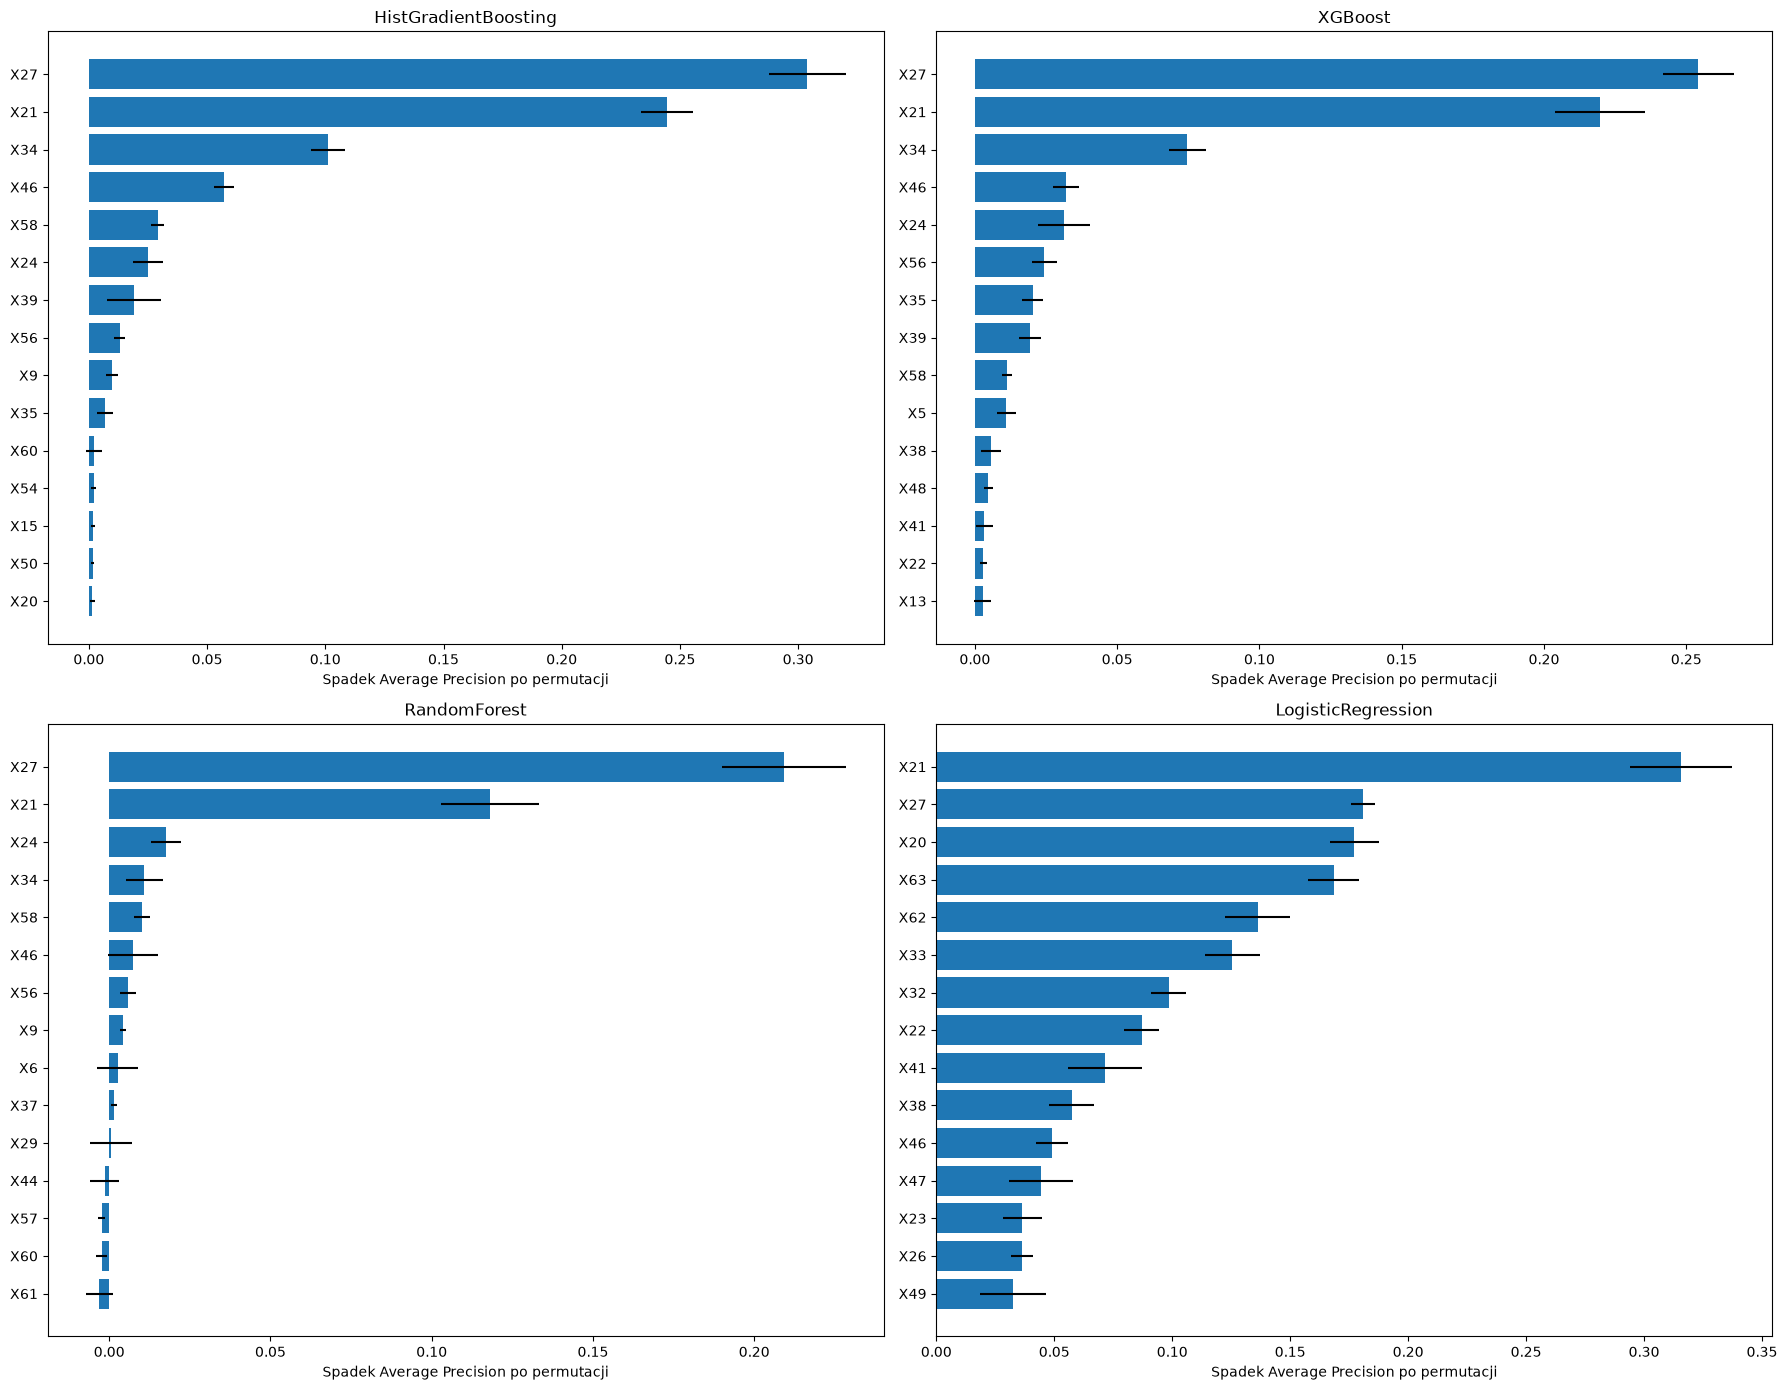

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
for ax, (nazwa, p) in zip(axes.flatten(), finalne.items()):
    imp = permutation_importance(p, X_test, y_test, scoring='average_precision',
                                 n_repeats=5, random_state=42, n_jobs=1)
    idx = np.argsort(imp.importances_mean)[-15:]
    ax.barh(X.columns[idx], imp.importances_mean[idx], xerr=imp.importances_std[idx])
    ax.set_title(nazwa)
    ax.set_xlabel('Spadek Average Precision po permutacji')
plt.tight_layout()
plt.show()

## 12. Wnioski

In [13]:
print('Ranking CV (AP):')
for _, r in ranking.iterrows():
    print(f"{r['Model']} [{r['Imputacja']}]: AP={r['AP']:.4f}±{r['AP_STD']:.4f}, ROC-AUC={r['ROC_AUC']:.4f}")
print('\nRanking test (AP):')
for _, r in wyniki_test.iterrows():
    print(f"{r['Model']}: AP={r['AP']:.4f}, ROC-AUC={r['ROC_AUC']:.4f}, F1={r['F1']:.3f}")
print('\nNajlepszy model (CV):', ranking.iloc[0]['Model'])

Ranking CV (AP):
HistGradientBoosting [mediana+wskaźnik]: AP=0.7831±0.0409, ROC-AUC=0.9510
XGBoost [mediana+wskaźnik]: AP=0.7686±0.0527, ROC-AUC=0.9459
LogisticRegression [stała+wskaźnik]: AP=0.6682±0.0665, ROC-AUC=0.9310
RandomForest [stała+wskaźnik]: AP=0.6020±0.0507, ROC-AUC=0.9320

Ranking test (AP):
HistGradientBoosting: AP=0.8475, ROC-AUC=0.9697, F1=0.815
XGBoost: AP=0.8297, ROC-AUC=0.9613, F1=0.771
LogisticRegression: AP=0.7209, ROC-AUC=0.9435, F1=0.646
RandomForest: AP=0.6532, ROC-AUC=0.9530, F1=0.644

Najlepszy model (CV): HistGradientBoosting



## 13. Wpływ sposobu obsługi brakujących danych na skuteczność modelu XGBoost

Celem eksperymentu jest zbadanie wpływu sposobu obsługi brakujących wartości na skuteczność predykcji bankructwa przedsiębiorstw z wykorzystaniem 64 wskaźników finansowych.

Przeanalizowano dwa warianty modelu XGBoost:

1. **Mediana** – wszystkie brakujące wartości zastąpiono medianą odpowiedniego wskaźnika.
2. **Natywna obsługa braków (NaN)** – brakujące wartości pozostawiono bez uzupełnienia, wykorzystując mechanizm obsługi braków dostępny w XGBoost.

W celu zapewnienia porównywalności wyników w obu wariantach zastosowano identyczne parametry modelu oraz jednakowy podział danych. Przyjęto standardowy próg klasyfikacji równy 0,5, bez jego optymalizacji. Pozwoliło to ocenić wpływ sposobu obsługi brakujących wartości na skuteczność predykcji bankructwa przedsiębiorstw.

Skuteczność modeli oceniono za pomocą Average Precision (AP), ROC-AUC oraz Accuracy. Dodatkowo określono liczbę wykrytych i przeoczonych bankructw.


In [14]:

warianty = {
    "Mediana": zbuduj("XGBoost", "mediana"),
    "Natywne NaN": clone(modele["XGBoost"])
}

wyniki = []

for nazwa, model in warianty.items():
    s = cross_validate(model, X_train, y_train, cv=cv,
                       scoring=metryki, n_jobs=1)

    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    pred = p >= 0.5

    wyniki.append({
        "Metoda": nazwa,
        "AP_CV": s["test_AP"].mean(),
        "AP_std": s["test_AP"].std(),
        "AP_test": average_precision_score(y_test, p),
        "ROC_AUC": roc_auc_score(y_test, p),
        "Accuracy": (pred == y_test).mean(),
        "Wykryte": ((pred == 1) & (y_test == 1)).sum(),
        "Przeoczone": ((pred == 0) & (y_test == 1)).sum(),
        "Fałszywe alarmy": ((pred == 1) & (y_test == 0)).sum()
    })

display(pd.DataFrame(wyniki).round(4))


,Metoda,AP_CV,AP_std,AP_test,ROC_AUC,Accuracy,Wykryte,Przeoczone,Fałszywe alarmy
0,Mediana,0.7327,0.0475,0.8169,0.9578,0.9641,45,37,5
1,Natywne NaN,0.7632,0.0582,0.8260,0.9597,0.9684,53,29,8


### 13.2. Wpływ usunięcia wskaźników X21 i X27 na skuteczność modelu XGBoost

W kolejnym eksperymencie zbadaliśmy wpływ dwóch wskaźników finansowych, X21 i X27, na skuteczność predykcji bankructwa przedsiębiorstw. We wcześniejszej analizie ważności permutacyjnej wskaźniki te osiągnęły najwyższe wyniki.

Porównaliśmy model XGBoost wykorzystujący wszystkie 64 wskaźniki z modelem opartym na 62 wskaźnikach, po usunięciu X21 i X27. Zachowaliśmy identyczne hiperparametry oraz pięciokrotną stratyfikowaną walidację krzyżową.

Po usunięciu tych dwóch wskaźników średnia wartość AP zmniejszyła się z 0,7632 do 0,5176, a ROC-AUC z 0,9451 do 0,8834. Wyniki wskazują na duże znaczenie X21 i X27 dla skuteczności modelu.


In [15]:

# Częstość braków w obu klasach
braki_21_27 = X_train[["X21", "X27"]].isna()

display(
    (braki_21_27.groupby(y_train).mean() * 100)
    .rename(index={0: "Bez bankructwa", 1: "Bankructwo"})
    .round(2)
)

# Model wykorzystujący wyłącznie flagi braków
s = cross_validate(
    clone(modele["XGBoost"]),
    braki_21_27.astype(int), y_train,
    cv=cv, scoring=metryki, n_jobs=1
)

print("AP:", round(s["test_AP"].mean(), 4))
print("ROC-AUC:", round(s["test_ROC_AUC"].mean(), 4))
print("Baseline AP:", round(y_train.mean(), 4))


,X21,X27
y,,
Bez bankructwa,0.05,5.12
Bankructwo,23.62,28.83


AP: 0.1379
ROC-AUC: 0.6185
Baseline AP: 0.0697


### Wnioski z eksperymentów

Zaobserwowaliśmy, że brakujące wartości X21 i X27 występują znacznie częściej wśród przedsiębiorstw, które zbankrutowały. Dodatkowo model wykorzystujący wyłącznie informację o brakach tych dwóch wskaźników osiągnął AP = 0,1379, przewyższając punkt odniesienia wynoszący 0,0697.

Wyniki wskazują, że informacja o niedostępności X21 i X27 jest powiązana z ryzykiem bankructwa. Jednocześnie nie możemy jednoznacznie określić, jaka część skuteczności pełnego modelu wynika z wartości liczbowych tych wskaźników, a jaka z występujących w nich braków.

Z tego względu w dalszych badaniach ograniczyliśmy zestaw cech do 13 wskaźników, uwzględniając ich znaczenie predykcyjne, interpretację ekonomiczną i matematyczną oraz możliwość praktycznego pozyskania danych.


### 13.3. Analiza statystyczna brakujących wartości X21 i X27

W celu pogłębienia wcześniejszych eksperymentów zbadamy
zależność pomiędzy występowaniem brakujących wartości
wskaźników X21 i X27 a bankructwem przedsiębiorstwa.

Wykorzystamy dokładny test Fishera, iloraz szans (OR)
oraz 95-procentowe przedziały ufności.

Hipoteza zerowa zakłada niezależność występowania
brakujących wartości i klasy przedsiębiorstwa.

Analizę przeprowadzimy wyłącznie na zbiorze treningowym.

In [19]:
from scipy.stats import fisher_exact

for cecha in ["X21", "X27"]:
    tabela = pd.crosstab(X_train[cecha].isna(), y_train)
    OR, p = fisher_exact(tabela)

    print(f"\n{cecha}")
    display(tabela)
    print(f"Iloraz szans: {OR:.2f}")
    print(f"p-value: {p:.4e}")


X21


y,0,1
X21,,
False,4352,249
True,2,77


Iloraz szans: 672.90
p-value: 2.3889e-90

X27


y,0,1
X27,,
False,4131,232
True,223,94


Iloraz szans: 7.51
p-value: 2.8541e-38


In [20]:
X62 = X_train.drop(columns=["X21", "X27"])
flagi = X_train[["X21", "X27"]].isna().astype(int)
flagi.columns = ["M21", "M27"]

warianty = {
    "64 wskaźniki": X_train,
    "63 bez X21": X_train.drop(columns="X21"),
    "63 bez X27": X_train.drop(columns="X27"),
    "62 wskaźniki": X62,
    "62 + flaga X21": X62.join(flagi[["M21"]]),
    "62 + flaga X27": X62.join(flagi[["M27"]]),
    "62 + obie flagi": X62.join(flagi)
}

wyniki = []

for nazwa, X in warianty.items():
    s = cross_validate(
        clone(modele["XGBoost"]),
        X, y_train,
        cv=cv,
        scoring="average_precision"
    )

    wyniki.append({
        "Wariant": nazwa,
        "AP": s["test_score"].mean(),
        "AP_STD": s["test_score"].std()
    })

display(pd.DataFrame(wyniki).round(4))

,Wariant,AP,AP_STD
0,64 wskaźniki,0.7632,0.0582
1,63 bez X21,0.6803,0.0566
2,63 bez X27,0.6434,0.0541
3,62 wskaźniki,0.5176,0.0515
4,62 + flaga X21,0.6246,0.0664
5,62 + flaga X27,0.6805,0.0495
6,62 + obie flagi,0.7647,0.0453


### Wnioski z analizy X21 i X27

Test dokładny Fishera wykazał istotny statystycznie
związek pomiędzy występowaniem brakujących wartości
wskaźników X21 i X27 a bankructwem przedsiębiorstwa.

Usunięcie obu wskaźników spowodowało spadek średniej
wartości AP z 0,7632 do 0,5176. Zastąpienie ich
binarnymi flagami braków pozwoliło uzyskać AP = 0,7647.

Otrzymane wyniki wskazują, że informacja o występowaniu
brakujących wartości stanowi silny sygnał predykcyjny
w analizowanym zbiorze danych.

Ze względu na nieznany mechanizm powstawania braków
oraz brak gwarancji zachowania tych zależności
w rzeczywistych warunkach użytkowania systemu,
zasadne jest rozważenie wykluczenia tych wskaźników
z modelu końcowego.

## 14. Analiza wpływu metod obsługi brakujących danych na skuteczność modeli uczenia maszynowego dla 13 wskaźników finansowych

W kolejnym etapie badań wykorzystamy ograniczony zbiór obejmujący 13 wskaźników finansowych:

**X1, X2, X3, X5, X6, X24, X29, X34, X35, X46, X56, X58 oraz X62.**

Wybrane wskaźniki opisują różne obszary kondycji finansowej przedsiębiorstwa, takie jak rentowność, płynność finansowa, zadłużenie, koszty działalności, historia wyników finansowych oraz wielkość przedsiębiorstwa.

Celem eksperymentów jest zbadanie wpływu różnych metod obsługi brakujących wartości na skuteczność predykcji bankructwa oraz wyznaczenie najkorzystniejszej konfiguracji modelu.

W ramach badania zaplanowaliśmy **12 eksperymentów**, obejmujących cztery sposoby przetwarzania danych:

1. **Imputacja medianą (4 eksperymenty)** – zastąpimy wszystkie brakujące wartości medianą odpowiedniego wskaźnika.
2. **Imputacja medianą z flagą braków (4 eksperymenty)** – uzupełnimy braki medianą oraz dodamy zmienne binarne informujące o pierwotnym występowaniu brakujących wartości.
3. **Natywna obsługa braków (2 eksperymenty)** – pozostawimy wartości `NaN` w modelach XGBoost oraz HistGradientBoosting.
4. **Imputacja hybrydowa (2 eksperymenty)** – selektywnie uzupełnimy medianą wskaźniki X1, X2, X3, X6, X29 i X35, natomiast braki w pozostałych wskaźnikach pozostawimy bez zmian. W tym wariancie wykorzystamy modele XGBoost i HistGradientBoosting.

W eksperymentach wykorzystamy cztery algorytmy: Logistic Regression, Random Forest, HistGradientBoosting oraz XGBoost.

W celu zachowania porównywalności wyników zastosujemy jednakowy podział danych oraz pięciokrotną stratyfikowaną walidację krzyżową. Jako główną miarę oceny przyjmiemy Average Precision (AP). Dodatkowo przeanalizujemy ROC-AUC, Accuracy, Recall, Precision oraz F2.

Na podstawie przeprowadzonych eksperymentów określimy, która metoda obsługi brakujących wartości zapewnia najlepszą skuteczność predykcji bankructwa przedsiębiorstw na ograniczonym zbiorze wskaźników finansowych.


### 14.1. Uzupełnianie brakujących wartości medianą

W pierwszym eksperymencie zastosujemy imputację medianą dla wszystkich 13 wybranych wskaźników finansowych. Brakujące wartości zastąpimy medianą odpowiedniego wskaźnika, wyznaczoną na podstawie danych treningowych.

Przeprowadzimy eksperymenty dla czterech modeli:
- HistGradientBoosting,
- XGBoost,
- Random Forest,
- Logistic Regression.

Do oceny skuteczności wykorzystamy pięciokrotną stratyfikowaną walidację krzyżową oraz metryki AP, ROC-AUC i Accuracy.


In [ ]:
# 13 wybranych wskaźników
cechy_13 = [
    "X1", "X2", "X3", "X5", "X6", "X24", "X29",
    "X34", "X35", "X46", "X56", "X58", "X62"
]

X_train_13 = X_train[cechy_13]

wyniki_mediana = []

for nazwa in modele:
    s = cross_validate(
        zbuduj(nazwa, "mediana"),
        X_train_13, y_train,
        cv=cv,
        scoring={**metryki, "Accuracy": "accuracy"},
        n_jobs=1
    )

    wyniki_mediana.append({
        "Model": nazwa,
        "Metoda": "mediana",
        "AP": s["test_AP"].mean(),
        "AP_std": s["test_AP"].std(),
        "ROC_AUC": s["test_ROC_AUC"].mean(),
        "Accuracy_0_5": s["test_Accuracy"].mean()
    })

wyniki_mediana = pd.DataFrame(wyniki_mediana)
display(wyniki_mediana.sort_values("AP", ascending=False).round(4))


,Model,Metoda,AP,AP_std,ROC_AUC,Accuracy_0_5
0,HistGradientBoosting,mediana,0.5645,0.0299,0.8805,0.9468
1,XGBoost,mediana,0.5336,0.0320,0.8748,0.9436
2,RandomForest,mediana,0.4866,0.0333,0.8864,0.9380
3,LogisticRegression,mediana,0.3806,0.0460,0.8294,0.7784



### 14.2. Imputacja medianą z flagą brakujących wartości

W drugim eksperymencie zastosujemy imputację medianą z dodatkową flagą informującą o występowaniu brakujących wartości. Dla wskaźników zawierających braki utworzymy zmienne binarne przyjmujące wartość 1, jeśli wartość wskaźnika była pierwotnie brakująca, oraz 0 w przeciwnym przypadku.

Wykorzystamy te same cztery modele, parametry oraz procedurę walidacji krzyżowej co w pierwszym eksperymencie.


In [ ]:
wyniki_flaga = []

for nazwa in modele:
    s = cross_validate(
        zbuduj(nazwa, "mediana+wskaźnik"),
        X_train_13, y_train,
        cv=cv,
        scoring={**metryki, "Accuracy": "accuracy"},
        n_jobs=1
    )

    wyniki_flaga.append({
        "Model": nazwa,
        "Metoda": "mediana+flaga",
        "AP": s["test_AP"].mean(),
        "AP_std": s["test_AP"].std(),
        "ROC_AUC": s["test_ROC_AUC"].mean(),
        "Accuracy_0_5": s["test_Accuracy"].mean()
    })

wyniki_flaga = pd.DataFrame(wyniki_flaga)
display(wyniki_flaga.sort_values("AP", ascending=False).round(4))


,Model,Metoda,AP,AP_std,ROC_AUC,Accuracy_0_5
0,HistGradientBoosting,mediana+flaga,0.5695,0.0298,0.8851,0.9468
1,XGBoost,mediana+flaga,0.5339,0.0293,0.8783,0.9436
2,RandomForest,mediana+flaga,0.4818,0.0403,0.8858,0.9348
3,LogisticRegression,mediana+flaga,0.3951,0.0398,0.8315,0.7829



### 14.3. Natywna obsługa brakujących wartości

W trzecim eksperymencie pozostawimy brakujące wartości bez uzupełniania, wykorzystując natywną obsługę braków w modelach HistGradientBoosting oraz XGBoost.

Zachowamy wcześniejsze parametry modeli oraz pięciokrotną stratyfikowaną walidację krzyżową. Skuteczność ocenimy za pomocą tych samych metryk co w poprzednich eksperymentach.


In [ ]:

wyniki_nan = []

for nazwa in ["HistGradientBoosting", "XGBoost"]:
    s = cross_validate(
        clone(modele[nazwa]),
        X_train_13, y_train,
        cv=cv,
        scoring={**metryki, "Accuracy": "accuracy"},
        n_jobs=1
    )

    wyniki_nan.append({
        "Model": nazwa,
        "Metoda": "natywne_NaN",
        "AP": s["test_AP"].mean(),
        "AP_std": s["test_AP"].std(),
        "ROC_AUC": s["test_ROC_AUC"].mean(),
        "Accuracy_0_5": s["test_Accuracy"].mean()
    })

wyniki_nan = pd.DataFrame(wyniki_nan)
display(wyniki_nan.sort_values("AP", ascending=False).round(4))


,Model,Metoda,AP,AP_std,ROC_AUC,Accuracy_0_5
0,HistGradientBoosting,natywne_NaN,0.5642,0.0240,0.8810,0.9462
1,XGBoost,natywne_NaN,0.5386,0.0273,0.8753,0.9438


### 14.4. Hybrydowa obsługa brakujących wartości

W czwartym eksperymencie zastosujemy hybrydową metodę obsługi brakujących danych, uwzględniającą matematyczną i ekonomiczną interpretację wskaźników finansowych.

Medianą uzupełnimy brakujące wartości wskaźników X1, X2, X3, X6, X29 i X35, natomiast w pozostałych siedmiu wskaźnikach pozostawimy wartości NaN.

Eksperyment przeprowadzimy dla modeli HistGradientBoosting oraz XGBoost, zachowując wcześniejsze parametry i procedurę walidacji krzyżowej.


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

cechy_mediana = ["X1", "X2", "X3", "X6", "X29", "X35"]

hybryda = ColumnTransformer([
    ("mediana", SimpleImputer(strategy="median"), cechy_mediana)
], remainder="passthrough")

wyniki_hybryda = []

for nazwa in ["HistGradientBoosting", "XGBoost"]:
    model = Pipeline([
        ("imputer", clone(hybryda)),
        ("model", clone(modele[nazwa]))
    ])

    s = cross_validate(
        model, X_train_13, y_train,
        cv=cv,
        scoring={**metryki, "Accuracy": "accuracy"},
        n_jobs=1
    )

    wyniki_hybryda.append({
        "Model": nazwa,
        "Metoda": "hybryda",
        "AP": s["test_AP"].mean(),
        "AP_std": s["test_AP"].std(),
        "ROC_AUC": s["test_ROC_AUC"].mean(),
        "Accuracy_0_5": s["test_Accuracy"].mean()
    })

wyniki_hybryda = pd.DataFrame(wyniki_hybryda)
display(wyniki_hybryda.sort_values("AP", ascending=False).round(4))


,Model,Metoda,AP,AP_std,ROC_AUC,Accuracy_0_5
0,HistGradientBoosting,hybryda,0.5633,0.0262,0.8840,0.9451
1,XGBoost,hybryda,0.5393,0.0311,0.8775,0.9449


### 14.5. Zestawienie wyników eksperymentów

In [ ]:

wyniki_wszystkie = pd.concat([
    wyniki_mediana,
    wyniki_flaga,
    wyniki_nan,
    wyniki_hybryda
], ignore_index=True)

wyniki_wszystkie = (
    wyniki_wszystkie
    .sort_values("AP", ascending=False)
    .reset_index(drop=True)
)

display(wyniki_wszystkie.round(4))


,Model,Metoda,AP,AP_std,ROC_AUC,Accuracy_0_5
0,HistGradientBoosting,mediana+flaga,0.5695,0.0298,0.8851,0.9468
1,HistGradientBoosting,mediana,0.5645,0.0299,0.8805,0.9468
2,HistGradientBoosting,natywne_NaN,0.5642,0.0240,0.8810,0.9462
3,HistGradientBoosting,hybryda,0.5633,0.0262,0.8840,0.9451
4,XGBoost,natywne_NaN,0.5386,0.0273,0.8753,0.9438
5,XGBoost,hybryda,0.5353,0.0249,0.8764,0.9444
6,XGBoost,mediana,0.5344,0.0333,0.8756,0.9442
7,XGBoost,mediana+flaga,0.5339,0.0293,0.8783,0.9436
8,RandomForest,mediana,0.4849,0.0319,0.8853,0.9374
9,RandomForest,mediana+flaga,0.4818,0.0403,0.8858,0.9348



Zestawiliśmy wyniki wszystkich 12 eksperymentów, porządkując je według średniej wartości Average Precision uzyskanej w walidacji krzyżowej.

Najwyższy wynik osiągnął model HistGradientBoosting z imputacją medianą i flagą brakujących wartości (AP = 0,5695). W przypadku XGBoost najlepsza okazała się natywna obsługa braków (AP = 0,5386).

Zauważyliśmy, że różnice pomiędzy metodami obsługi braków dla tego samego algorytmu były niewielkie. Dla HistGradientBoosting różnica między najwyższym i najniższym wynikiem AP wyniosła 0,0062, natomiast dla XGBoost 0,0047.

Znacznie większe różnice zaobserwowaliśmy pomiędzy poszczególnymi algorytmami. Wyniki wskazują zatem, że w analizowanym eksperymencie wybór modelu miał większe znaczenie niż zastosowana metoda obsługi brakujących wartości.



### 14.6. Wnioski z eksperymentów

W ramach przeprowadzonych 12 eksperymentów zbadaliśmy wpływ czterech metod obsługi brakujących wartości na skuteczność modeli uczenia maszynowego wykorzystujących 13 wskaźników finansowych.

Najwyższą średnią wartość Average Precision (AP = 0,5695) osiągnął model HistGradientBoosting z imputacją medianą i flagą brakujących wartości. W przypadku XGBoost najlepszy wynik uzyskaliśmy przy natywnej obsłudze braków (AP = 0,5386).

Zaobserwowaliśmy, że różnice pomiędzy metodami obsługi braków w obrębie poszczególnych modeli były niewielkie. Metoda hybrydowa również zapewniła zbliżone wyniki, osiągając AP = 0,5633 dla HistGradientBoosting oraz AP = 0,5353 dla XGBoost.

Pomimo uzyskania najwyższego wyniku przez HistGradientBoosting z imputacją medianą i flagą braków, nie zdecydowaliśmy się na jego ostateczny wybór. W przypadku części wskaźników finansowych zastąpienie brakujących wartości medianą może nie być uzasadnione z matematycznego i ekonomicznego punktu widzenia. Takie przetwarzanie nie odtwarza rzeczywistych wartości wskaźników i może wpływać na ich interpretację.

Z tego względu do kolejnego etapu badań wybraliśmy model XGBoost z natywną obsługą brakujących wartości. Rozwiązanie to pozwala uniknąć konieczności imputacji danych, zachowując jednocześnie możliwość wykorzystania dostępnych informacji finansowych.

!!!!!!!!!!!!!!!!!!!!! HGB jednak zostawiam, bo jednak mozna go optymalizować!!!!!!!!!!!!!!
Dalszą optymalizację modelu HistGradientBoosting wstrzymaliśmy. Jako alternatywę pozostawiliśmy metodę hybrydową, w której część brakujących wartości uzupełniamy medianą, a pozostałe pozostawiamy bez zmian.

!!!!!!!!!!!!!!!!11 to jeszcze zobaczyć jak po optymalizacji bedzie, na co sie zdecydujemy!!!!!!!!!!!!!!!
Pomimo uzyskania najwyższego wyniku przez HistGradientBoosting z imputacją medianą i flagą braków, nie zdecydowaliśmy się na ten wariant. W przypadku części wskaźników finansowych zastąpienie brakujących wartości medianą może nie być uzasadnione z matematycznego i ekonomicznego punktu widzenia. Takie przetwarzanie nie odtwarza rzeczywistych wartości wskaźników i może wpływać na ich interpretację.

Z tego względu do kolejnego etapu badań wybraliśmy modele XGBoost i HistGradientBoosting z natywną obsługą brakujących wartości, które nie wymagają imputacji danych. Ograniczenie dotyczy wyłącznie wariantu z imputacją, a nie samego modelu HistGradientBoosting: przy natywnej obsłudze braków osiągnął on AP = 0,5642, wobec 0,5386 dla XGBoost. Ponieważ różnica ta jest porównywalna z odchyleniem standardowym wyników w foldach, ostateczny wybór modelu podejmiemy po optymalizacji hiperparametrów i doborze progu klasyfikacji. Jako alternatywę pozostawiliśmy metodę hybrydową, w której część brakujących wartości uzupełniamy medianą, a pozostałe pozostawiamy bez zmian.


Ostateczną ocenę wybranego rozwiązania przeprowadzimy po optymalizacji hiperparametrów i doborze progu klasyfikacji.


## 15. Optymalizacja modeli XGBoost i HistGradientBoosting


### 15.1. Charakter braków w 13 wskaźnikach - podstawa podziału na wskaźniki uzupełniane medianą i pozostawiane bez zmian

Zanim przejdziemy do optymalizacji modeli, sprawdzimy, skąd biorą się braki w wybranych 13 wskaźnikach. Ma to znaczenie dla sposobu ich obsługi, ponieważ wskaźniki finansowe są ilorazami, a brak wartości może mieć dwa różne źródła:

- **brak techniczny** – pozycji nie wprowadzono do sprawozdania, a mianownik wskaźnika (np. aktywa ogółem) nie jest zerem. Brak nie niesie informacji o kondycji firmy, więc uzupełnienie medianą niczego nie zniekształca;
- **brak strukturalny** – iloraz nie istnieje, ponieważ mianownik wynosi zero (firma bez zobowiązań, bez sprzedaży) albo brakuje danych historycznych (np. 3-letniego zysku młodej firmy). Taki brak jest informacją o przedsiębiorstwie, a mediana zastąpiłaby ją wartością „typowej” firmy, której w rzeczywistości nie ma.


**Wnioski z analizy braków**

Braki w wybranych 13 wskaźnikach są nieliczne: dotyczą 165 z 5850 przedsiębiorstw (2,82%).

- **X1, X2, X3, X6, X29 i X35** brakują w dokładnie tych samych 3 rekordach, w których brakuje 7-9 z 13 wskaźników (praktycznie puste sprawozdania). Mianownikiem jest wielkość aktywów ogółem, która dla działającego przedsiębiorstwa nie jest zerem, więc są to braki techniczne. Uzupełnienie ich medianą dotyczy zaledwie 3 wierszy i nie zniekształca informacji o ryzyku – dlatego w wariancie hybrydowym uzupełniamy te wskaźniki medianą.
- **X24** (zysk brutto z 3 lat / aktywa ogółem) ma najwięcej braków (135, czyli 2,31%). Brak oznacza przedsiębiorstwo bez 3-letniej historii wyników. Wśród takich firm bankructwo wystąpiło tylko raz, przy czym ten przypadek pochodzi z jednego z pustych rekordów – wśród 132 firm z izolowanym brakiem X24 nie ma żadnego bankruta. Brak jest więc informacją o firmie, a nie losowym błędem, i zastąpienie go medianą zatarłoby ten sygnał. Warto jednak pamiętać, że może to być cecha konstrukcji próby, a nie prawidłowość ekonomiczna: młode przedsiębiorstwo w praktyce również może zbankrutować.
- **X34 i X46** brakują razem w 16 rekordach (firma bez zobowiązań - mianownik równy zero), a X46 dodatkowo w 3 kolejnych (brak zobowiązań krótkoterminowych). **X5** brakuje w 11 rekordach, w których mianownik (koszty operacyjne - amortyzacja) może wynosić zero. Są to braki strukturalne, choć bardzo nieliczne (0,19–0,36%). Związek z bankructwem nie jest istotny statystycznie, więc o pozostawieniu NaN decyduje interpretacja ekonomiczna, a nie test.
- **X56, X58 i X62** (mianownik: sprzedaż) nie mają w tej bazie żadnych braków. Pozostawiamy je w zestawie NaN dla spójności z wariantem hybrydowym.

Ponieważ braków jest niewiele, sposób ich obsługi miał w rozdziale 14 niewielki wpływ na AP. Podział na wskaźniki uzupełniane medianą i pozostawiane bez zmian uzasadniamy więc interpretacją ekonomiczną (mianownik wskaźnika) oraz analizą braków w X24, a nie wynikiem modeli.

### 15.2. Optymalizacja hiperparametrów

Do optymalizacji wykorzystamy losowe przeszukiwanie hiperparametrów (`RandomizedSearchCV`) na zbiorze treningowym, z tą samą pięciokrotną stratyfikowaną walidacją krzyżową co w poprzednich eksperymentach i metryką Average Precision. Poza standardowymi hiperparametrami przeszukamy także wagę klasy bankrutów (`scale_pos_weight` w XGBoost, `class_weight` w HistGradientBoosting), ponieważ bankructwa stanowią tylko około 7% obserwacji.

Zbiór testowy nie bierze udziału w strojeniu. Próg klasyfikacji wyznaczymy na predykcjach out-of-fold ze zbioru treningowego (maksimum F1), tak jak w rozdziale 10.

Ustawienia znajdują się na początku pierwszej komórki poniżej: można w nich wybrać modele, sposób obsługi braków (natywne NaN albo hybryda) oraz bazy do policzenia. Dla pozostałych baz (4year, 3year) wystarczy umieścić pliki `.arff` w folderze z notebookiem – zostaną wczytane i podzielone tak samo jak 5year (rozdziały 2 i 6).


In [ ]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

# ustawienia
modele_15 = ["XGBoost", "HistGradientBoosting"]   # po wyborze jednego modelu zostaw tylko jego
obsluga_brakow = "natywne_NaN"                    # "natywne_NaN" albo "hybryda" (mediana dla cechy_mediana, reszta NaN)
n_iter = 30                                       # liczba prób losowego przeszukiwania
bazy = ["5year", "4year", "3year"]                # bazy do policzenia (brakujące pliki zostaną pominięte)

przestrzenie = {
    "XGBoost": {
        "model__n_estimators": randint(100, 600), "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_depth": randint(2, 6), "model__min_child_weight": randint(1, 15),
        "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.5, 0.5),
        "model__reg_lambda": loguniform(0.1, 20), "model__gamma": uniform(0, 3),
        "model__scale_pos_weight": [1, 2, 4, 8]
    },
    "HistGradientBoosting": {
        "model__max_iter": randint(100, 600), "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_leaf_nodes": randint(4, 32), "model__min_samples_leaf": randint(10, 80),
        "model__l2_regularization": loguniform(0.1, 30), "model__class_weight": [None, "balanced"]
    }
}


def model_13(nazwa):
    krok_modelu = ("model", clone(modele[nazwa]))
    if obsluga_brakow == "hybryda":
        return Pipeline([("imputer", clone(hybryda)), krok_modelu])
    return Pipeline([krok_modelu])


def policz_baze(X_tr, X_te, y_tr, y_te):
    X_tr, X_te = X_tr[cechy_13], X_te[cechy_13]
    wiersze, szukania, krzywe, dopasowane = [], {}, {}, {}

    for nazwa in modele_15:
        domyslny = model_13(nazwa)
        s = cross_validate(domyslny, X_tr, y_tr, cv=cv, scoring=metryki, n_jobs=1)

        szukaj = RandomizedSearchCV(
            model_13(nazwa), przestrzenie[nazwa], n_iter=n_iter, scoring="average_precision",
            cv=cv, random_state=42, n_jobs=1, refit=True)
        szukaj.fit(X_tr, y_tr)
        szukania[nazwa] = szukaj

        for wersja, estymator, ap_cv in [("domyślny", domyslny, s["test_AP"].mean()),
                                         ("po strojeniu", szukaj.best_estimator_, szukaj.best_score_)]:
            estymator = clone(estymator)
            oof = cross_val_predict(estymator, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
            pr, rc, th = precision_recall_curve(y_tr, oof)
            prog = th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]

            estymator.fit(X_tr, y_tr)
            proba = estymator.predict_proba(X_te)[:, 1]
            pred = (proba >= prog).astype(int)
            krzywe[(nazwa, wersja)] = precision_recall_curve(y_te, proba)[:2]
            dopasowane[(nazwa, wersja)] = estymator
            wiersze.append({
                "Model": nazwa, "Wersja": wersja, "AP (CV)": ap_cv,
                "AP (test)": average_precision_score(y_te, proba), "ROC_AUC (test)": roc_auc_score(y_te, proba),
                "Próg": prog, "Precision": precision_score(y_te, pred), "Recall": recall_score(y_te, pred),
                "F1": f1_score(y_te, pred)
            })

    return {"tabela": pd.DataFrame(wiersze), "szukania": szukania, "krzywe": krzywe,
            "estymatory": dopasowane, "X_te": X_te, "y_te": y_te}


,Model,Wersja,AP (CV),AP (test),ROC_AUC (test),Próg,Precision,Recall,F1
0,XGBoost,domyślny,0.5360,0.5696,0.8923,0.2773,0.5432,0.5366,0.5399
1,XGBoost,po strojeniu,0.5553,0.5785,0.8943,0.3537,0.5185,0.5122,0.5153
2,HistGradientBoosting,domyślny,0.5642,0.5420,0.9044,0.2694,0.4831,0.5244,0.5029
3,HistGradientBoosting,po strojeniu,0.5704,0.5802,0.9009,0.2423,0.5208,0.6098,0.5618


XGBoost – najlepsze parametry: {'colsample_bytree': 0.8162, 'gamma': 1.9006, 'learning_rate': 0.0498, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 300, 'reg_lambda': 0.5472, 'scale_pos_weight': 2, 'subsample': 0.8783}
HistGradientBoosting – najlepsze parametry: {'class_weight': None, 'l2_regularization': 0.1448, 'learning_rate': 0.0214, 'max_iter': 367, 'max_leaf_nodes': 10, 'min_samples_leaf': 11}


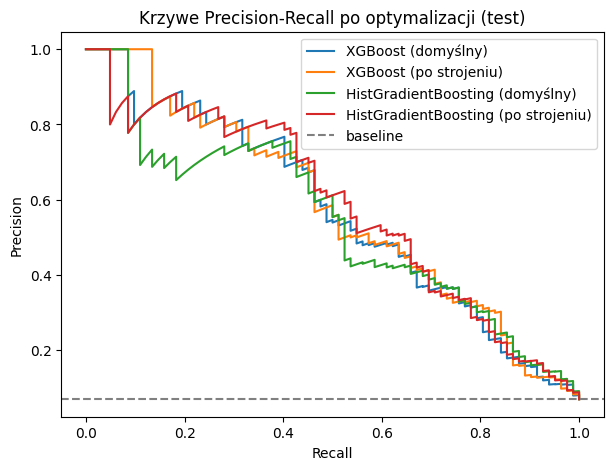

In [ ]:
# baza wczytana w rozdziałach 2 i 6 (bez ponownego przetwarzania danych)
wyniki_baz = {sciezka.stem: policz_baze(X_train, X_test, y_train, y_test)}
wynik = wyniki_baz[sciezka.stem]

display(wynik["tabela"].round(4))

for nazwa, szukaj in wynik["szukania"].items():
    parametry = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else (v.item() if hasattr(v, "item") else v))
                 for k, v in szukaj.best_params_.items()}
    print(f"{nazwa} – najlepsze parametry: {parametry}")

plt.figure(figsize=(7, 5))
for (nazwa, wersja), (pr, rc) in wynik["krzywe"].items():
    plt.plot(rc, pr, label=f"{nazwa} ({wersja})")
plt.axhline(y_test.mean(), ls="--", c="gray", label="baseline")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.title("Krzywe Precision-Recall po optymalizacji (test)")
plt.show()


In [ ]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

# ustawienia
modele_15 = ["XGBoost", "HistGradientBoosting"]   # po wyborze jednego modelu zostaw tylko jego
obsluga_brakow = "hybryda"                    # "natywne_NaN" albo "hybryda" (mediana dla cechy_mediana, reszta NaN)
n_iter = 30                                       # liczba prób losowego przeszukiwania
bazy = ["5year", "4year", "3year"]                # bazy do policzenia (brakujące pliki zostaną pominięte)

przestrzenie = {
    "XGBoost": {
        "model__n_estimators": randint(100, 600), "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_depth": randint(2, 6), "model__min_child_weight": randint(1, 15),
        "model__subsample": uniform(0.6, 0.4), "model__colsample_bytree": uniform(0.5, 0.5),
        "model__reg_lambda": loguniform(0.1, 20), "model__gamma": uniform(0, 3),
        "model__scale_pos_weight": [1, 2, 4, 8]
    },
    "HistGradientBoosting": {
        "model__max_iter": randint(100, 600), "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_leaf_nodes": randint(4, 32), "model__min_samples_leaf": randint(10, 80),
        "model__l2_regularization": loguniform(0.1, 30), "model__class_weight": [None, "balanced"]
    }
}


def model_13(nazwa):
    krok_modelu = ("model", clone(modele[nazwa]))
    if obsluga_brakow == "hybryda":
        return Pipeline([("imputer", clone(hybryda)), krok_modelu])
    return Pipeline([krok_modelu])


def policz_baze(X_tr, X_te, y_tr, y_te):
    X_tr, X_te = X_tr[cechy_13], X_te[cechy_13]
    wiersze, szukania, krzywe, dopasowane = [], {}, {}, {}

    for nazwa in modele_15:
        domyslny = model_13(nazwa)
        s = cross_validate(domyslny, X_tr, y_tr, cv=cv, scoring=metryki, n_jobs=1)

        szukaj = RandomizedSearchCV(
            model_13(nazwa), przestrzenie[nazwa], n_iter=n_iter, scoring="average_precision",
            cv=cv, random_state=42, n_jobs=1, refit=True)
        szukaj.fit(X_tr, y_tr)
        szukania[nazwa] = szukaj

        for wersja, estymator, ap_cv in [("domyślny", domyslny, s["test_AP"].mean()),
                                         ("po strojeniu", szukaj.best_estimator_, szukaj.best_score_)]:
            estymator = clone(estymator)
            oof = cross_val_predict(estymator, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
            pr, rc, th = precision_recall_curve(y_tr, oof)
            prog = th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]

            estymator.fit(X_tr, y_tr)
            proba = estymator.predict_proba(X_te)[:, 1]
            pred = (proba >= prog).astype(int)
            krzywe[(nazwa, wersja)] = precision_recall_curve(y_te, proba)[:2]
            dopasowane[(nazwa, wersja)] = estymator
            wiersze.append({
                "Model": nazwa, "Wersja": wersja, "AP (CV)": ap_cv,
                "AP (test)": average_precision_score(y_te, proba), "ROC_AUC (test)": roc_auc_score(y_te, proba),
                "Próg": prog, "Precision": precision_score(y_te, pred), "Recall": recall_score(y_te, pred),
                "F1": f1_score(y_te, pred)
            })

    return {"tabela": pd.DataFrame(wiersze), "szukania": szukania, "krzywe": krzywe,
            "estymatory": dopasowane, "X_te": X_te, "y_te": y_te}


,Model,Wersja,AP (CV),AP (test),ROC_AUC (test),Próg,Precision,Recall,F1
0,XGBoost,domyślny,0.5393,0.5610,0.8913,0.2017,0.4495,0.5976,0.5131
1,XGBoost,po strojeniu,0.5613,0.5728,0.8959,0.4043,0.5333,0.4878,0.5096
2,HistGradientBoosting,domyślny,0.5633,0.5496,0.9028,0.2625,0.5000,0.5366,0.5176
3,HistGradientBoosting,po strojeniu,0.5737,0.5596,0.8978,0.2345,0.5000,0.6098,0.5495


XGBoost – najlepsze parametry: {'colsample_bytree': 0.8162, 'gamma': 1.9006, 'learning_rate': 0.0498, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 300, 'reg_lambda': 0.5472, 'scale_pos_weight': 2, 'subsample': 0.8783}
HistGradientBoosting – najlepsze parametry: {'class_weight': None, 'l2_regularization': 0.1448, 'learning_rate': 0.0214, 'max_iter': 367, 'max_leaf_nodes': 10, 'min_samples_leaf': 11}


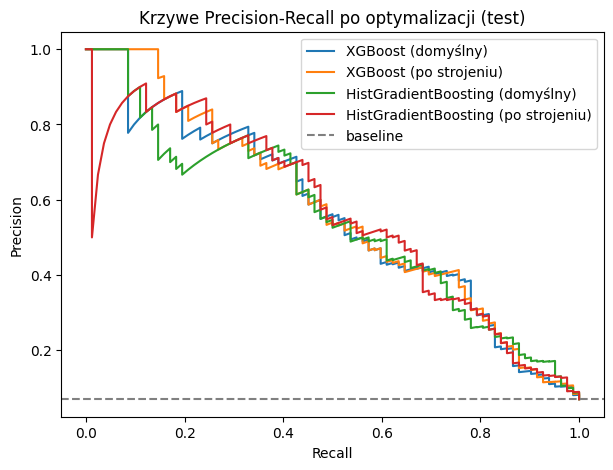

In [ ]:
# baza wczytana w rozdziałach 2 i 6 (bez ponownego przetwarzania danych)
wyniki_baz = {sciezka.stem: policz_baze(X_train, X_test, y_train, y_test)}
wynik = wyniki_baz[sciezka.stem]

display(wynik["tabela"].round(4))

for nazwa, szukaj in wynik["szukania"].items():
    parametry = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else (v.item() if hasattr(v, "item") else v))
                 for k, v in szukaj.best_params_.items()}
    print(f"{nazwa} – najlepsze parametry: {parametry}")

plt.figure(figsize=(7, 5))
for (nazwa, wersja), (pr, rc) in wynik["krzywe"].items():
    plt.plot(rc, pr, label=f"{nazwa} ({wersja})")
plt.axhline(y_test.mean(), ls="--", c="gray", label="baseline")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.title("Krzywe Precision-Recall po optymalizacji (test)")
plt.show()


Optymalizacja hiperparametrów poprawiła AP w walidacji krzyżowej obu modeli: dla XGBoost z 0,5360 do 0,5553, a dla HistGradientBoosting z 0,5642 do 0,5704 (natywna obsługa braków). Najwyższy AP w CV osiągnął HistGradientBoosting (0,5704 przy natywnej obsłudze braków i 0,5737 w wariancie hybrydowym), a XGBoost po optymalizacji uzyskał odpowiednio 0,5553 i 0,5613. Różnice między modelami (ok. 0,01–0,015) oraz między sposobami obsługi braków (ok. 0,003) są mniejsze niż odchylenie standardowe wyników w foldach (0,025–0,04), dlatego nie traktujemy ich jako istotnych. Na zbiorze testowym oba modele uzyskały zbliżone wyniki (AP = 0,5802 dla HistGradientBoosting i 0,5785 dla XGBoost), przy czym zbiór testowy zawiera tylko 82 bankrutów, więc różnice rzędu kilku setnych mieszczą się w niepewności oceny.

Do dalszych etapów wybieramy HistGradientBoosting z natywną obsługą brakujących wartości: model ten osiągnął najwyższy lub równorzędny wynik w walidacji krzyżowej i nie wymaga imputacji, a wariant hybrydowy nie poprawił wyniku.

### 15.4. Pozostałe bazy (4year i 3year)

Te same kroki (te same 13 wskaźników, ta sama obsługa braków i optymalizacja) powtórzymy dla pozostałych baz. Dla każdej z nich szukamy w folderze pliku `4year_13wskaznikow.arff` (same 13 wskaźników); analogicznie dla 3year. 

In [ ]:
def przygotuj_baze(plik):
    # wczytanie, usunięcie duplikatów (tylko w pełnym pliku z 64 wskaźnikami) i podział 80/20 jak w rozdziałach 2 i 6
    rek, _ = arff.loadarff(plik)
    Xb = pd.DataFrame({n.replace("Attr", "X"): rek[n].astype(float) for n in rek.dtype.names if n != "class"})
    yb = pd.Series([int(v.decode("ascii")) for v in rek["class"]], name="y")
    dane_b = pd.concat([Xb, yb], axis=1)
    if Xb.shape[1] == 64:
        dane_b = dane_b.drop_duplicates()
    dane_b = dane_b.reset_index(drop=True)
    yb = dane_b.pop("y")
    return train_test_split(dane_b, yb, test_size=0.2, stratify=yb, random_state=42)


for baza in bazy:
    if baza == sciezka.stem:
        continue
    plik = next((p for p in [sciezka.parent / f"{baza}.arff", sciezka.parent / f"{baza}_13wskaznikow.arff"] if p.exists()), None)
    if plik is None:
        print(f"{baza}: brak pliku {baza}.arff lub {baza}_13wskaznikow.arff w folderze – pomijamy")
        continue
    X_tr_b, X_te_b, y_tr_b, y_te_b = przygotuj_baze(plik)
    print(f"{baza} ({plik.name}): train {X_tr_b.shape}, test {X_te_b.shape} (bankructwa w teście: {y_te_b.mean():.2%})")
    wyniki_baz[baza] = policz_baze(X_tr_b, X_te_b, y_tr_b, y_te_b)

zestawienie_baz = pd.concat(
    [w["tabela"].assign(Baza=b) for b, w in wyniki_baz.items()], ignore_index=True
)[["Baza", "Model", "Wersja", "AP (CV)", "AP (test)", "ROC_AUC (test)", "Próg", "Precision", "Recall", "F1"]]
display(zestawienie_baz.round(4))


4year (4year.arff): train (7768, 64), test (1942, 64) (bankructwa w teście: 5.30%)
3year (3year.arff): train (8332, 64), test (2084, 64) (bankructwa w teście: 4.75%)


,Baza,Model,Wersja,AP (CV),AP (test),ROC_AUC (test),Próg,Precision,Recall,F1
0,5year,XGBoost,domyślny,0.5393,0.5610,0.8913,0.2017,0.4495,0.5976,0.5131
1,5year,XGBoost,po strojeniu,0.5613,0.5728,0.8959,0.4043,0.5333,0.4878,0.5096
2,5year,HistGradientBoosting,domyślny,0.5633,0.5496,0.9028,0.2625,0.5000,0.5366,0.5176
3,5year,HistGradientBoosting,po strojeniu,0.5737,0.5596,0.8978,0.2345,0.5000,0.6098,0.5495
4,4year,XGBoost,domyślny,0.3482,0.3884,0.8715,0.1906,0.4457,0.3981,0.4205
5,4year,XGBoost,po strojeniu,0.3785,0.4315,0.8911,0.2382,0.4105,0.3786,0.3939
6,4year,HistGradientBoosting,domyślny,0.3758,0.4346,0.8815,0.1595,0.4364,0.4660,0.4507
7,4year,HistGradientBoosting,po strojeniu,0.3828,0.4752,0.8805,0.0725,0.3473,0.5631,0.4296
8,3year,XGBoost,domyślny,0.2809,0.3231,0.8652,0.1333,0.3071,0.4343,0.3598
9,3year,XGBoost,po strojeniu,0.3409,0.3473,0.8662,0.2174,0.3504,0.4141,0.3796
